# Project: Retail Sales & Profitability Analysis
### Executive Summary
This project analyzes a synthetic dataset of a retail superstore to identify profitability drivers and operational bottlenecks. 
**Key Findings:**
* The company operates at a 12.5% profit margin, but regional losses (e.g., Texas, Ohio) are severely dragging down overall performance.
* These losses are not due to logistical costs, but rather an aggressive, uncapped promotional strategy. Discounts above 20% systematically result in negative margins.
* **Optimization:** A sensitivity analysis reveals that capping discounts at 20% for underperforming products—even under the worst-case assumption where we lose those entire orders alongside their profitable items—would increase overall profit by **+39.6%** and raise the company margin from 12.5% to **22.8%**.

---
### Step 1: Data Ingestion & Library Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os
from dotenv import load_dotenv
from sqlalchemy import create_engine

# Load environment variables
load_dotenv()

# Data Ingestion: Loading both Orders and Returns sheets
df_orders = pd.read_excel('Dataset/Sample-Superstore.xlsx', sheet_name='Orders')
df_returns = pd.read_excel('Dataset/Sample-Superstore.xlsx', sheet_name='Returns')

# Deduplicate Returns to order grain (800 rows / 296 unique orders).
# Without this, the line-grain x order-grain join fans out and multiplies returned lines.
df_returns = df_returns.drop_duplicates(subset=['Order ID'])

# Merge to flag returned items
df_sales = df_orders.merge(df_returns[['Order ID', 'Returned']], on='Order ID', how='left')
df_sales['Returned'] = df_sales['Returned'].fillna('No')

# General structure and data types
print('--- DataFrame Info ---')
print(df_sales.info())

print('\n--- Missing Values ---')
missing_values = df_sales.isnull().sum()
print(missing_values[missing_values > 0])

D:\Descargas\1-ANACONDA\Lib\site-packages\openpyxl\worksheet\header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


--- DataFrame Info ---
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9983 non-null   float64       
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category       9994 non-null   str           
 15  Sub-Categ

D:\Descargas\1-ANACONDA\Lib\site-packages\openpyxl\worksheet\header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


### Step 2: Data Cleaning & Preprocessing
* **Column Names:** Converted to `snake_case` for SQL compatibility.
* **Missing Values:** The 11 missing postal codes correspond exclusively to Burlington, Vermont. Instead of filling with 0, we impute its actual ZIP code ('05401'). We also convert the column to string, as ZIP codes are geographic identifiers, not mathematical integers.
* **Duplicates:** `Returns` is deduplicated to order grain (800 rows → 296 unique orders) to avoid join fan-out. The 16 remaining duplicate `order_id` + `product_id` line items are legitimate split shipments, so they are preserved.

In [2]:
# 1. Drop unnecessary columns and standardize names
df_sales = df_sales.drop(columns=['Row ID'], errors='ignore')
df_sales.columns = df_sales.columns.str.lower().str.replace(' ', '_').str.replace('-', '_')

# 2. Impute missing postal codes (Burlington, Vermont = '05401')
# First convert to string and remove '.0' float artifacts
df_sales['postal_code'] = df_sales['postal_code'].astype(str).str.replace(r'\.0$', '', regex=True)

# Now identify the missing values (which became the string 'nan') and impute the ZIP code
mask = (df_sales['city'] == 'Burlington') & (df_sales['state'] == 'Vermont') & (df_sales['postal_code'] == 'nan')
df_sales.loc[mask, 'postal_code'] = '05401'

# Finally, zero-pad all postal codes to ensure they have 5 digits
df_sales['postal_code'] = df_sales['postal_code'].str.zfill(5)

# 3. Handle Duplicates documentation
duplicates = df_sales[df_sales.duplicated(subset=['order_id', 'product_id'], keep=False)]
print(f"Found {len(duplicates)} duplicate line items. Preserved as legitimate split shipments.")

# 4. Verify
print("\n--- Cleaned Columns ---")
print(df_sales.columns.tolist())
display(df_sales.head(3))

Found 16 duplicate line items. Preserved as legitimate split shipments.

--- Cleaned Columns ---
['order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id', 'customer_name', 'segment', 'country', 'city', 'state', 'postal_code', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit', 'returned']


,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,state,...,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,returned
0,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,...,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.0,41.9136,No
1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,...,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.0,219.5820,No
2,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,...,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.0,6.8714,No


### Step 3: Exploratory Data Analysis (EDA)
#### Business Question 1: How did sales and profits evolve over time?
Analyzing YoY growth and monthly trends to identify seasonality. Q1 runs in SQL (`sql_queries/01_yearly_performance.sql`); pandas only prepares the time columns.

--- Yearly Financial Performance (SQL) ---


,order_year,total_revenue,total_profit,profit_margin_pct,yoy_sales_growth_pct,yoy_profit_growth_pct
0,2015,484247.50,49543.97,10.23,NaN,NaN
1,2016,470532.51,61618.60,13.10,-2.83,24.37
2,2017,609205.60,81795.17,13.43,29.47,32.74
3,2018,733215.26,93439.27,12.74,20.36,14.24


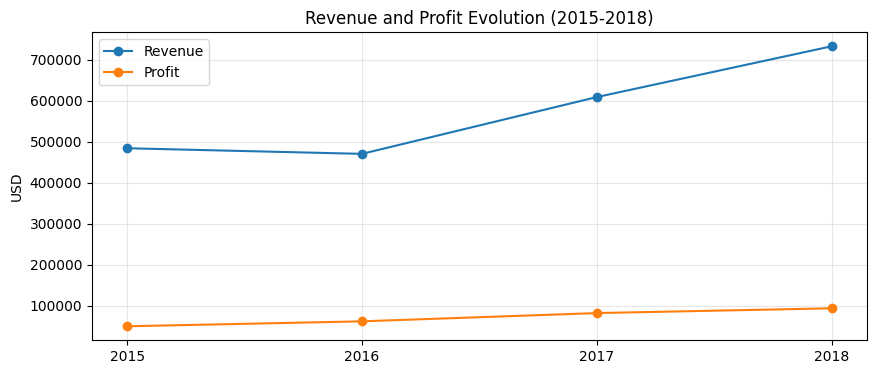

In [3]:
# 1. Create time-based columns (also needed for the DB table and the Looker CSV export)
df_sales['order_year'] = df_sales['order_date'].dt.year
df_sales['order_month_year'] = df_sales['order_date'].dt.to_period('M').astype(str)

# 2. Early load to Postgres so Q1 runs in SQL (the canonical ETL lives in Step 4)
from sqlalchemy import create_engine
import os
from dotenv import load_dotenv
load_dotenv()
_u = os.getenv('DB_USER') or 'postgres'
_p = os.getenv('DB_PASSWORD') or 'admin'
_h = os.getenv('DB_HOST') or 'localhost'
_pt = os.getenv('DB_PORT') or '5432'
_n = os.getenv('DB_NAME') or 'superstore_db'
engine = create_engine(f"postgresql://{_u}:{_p}@{_h}:{_pt}/{_n}")
df_sales.to_sql('sales_data', engine, if_exists='replace', index=False)

# 3. Q1 in SQL — same logic the notebook previously computed in pandas
with open('sql_queries/01_yearly_performance.sql', 'r') as file:
    yearly_metrics = pd.read_sql(file.read(), engine)
print("--- Yearly Financial Performance (SQL) ---")
display(yearly_metrics.round(2))

# 3. Visualize the trend
plt.figure(figsize=(10, 4))
plt.plot(yearly_metrics['order_year'].astype(str), yearly_metrics['total_revenue'], marker='o', label='Revenue')
plt.plot(yearly_metrics['order_year'].astype(str), yearly_metrics['total_profit'], marker='o', label='Profit')
plt.title('Revenue and Profit Evolution (2015-2018)')
plt.ylabel('USD')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Step 4: Database Integration (ETL - Load Phase)
Loading the structured dataset into a PostgreSQL database. **Note on Returns:** For this financial portfolio, we proceed analyzing the entire dataset (including returned items) to map historical accounting records accurately.

In [4]:
from sqlalchemy import create_engine
import os
from dotenv import load_dotenv

# Force reload of environment variables
load_dotenv()

# Setup PostgreSQL connection securely using environment variables
db_user = os.getenv('DB_USER')
db_pass = os.getenv('DB_PASSWORD')
db_host = os.getenv('DB_HOST')
db_port = os.getenv('DB_PORT')
db_name = os.getenv('DB_NAME')

# Security fallback: if .env is missing, use default local credentials
if db_user is None:
    print("WARNING: .env file not found or not loaded. Using default local credentials...")
    db_user, db_pass, db_host, db_port, db_name = 'postgres', 'admin', 'localhost', '5432', 'superstore_db'

engine_url = f"postgresql://{db_user}:{db_pass}@{db_host}:{db_port}/{db_name}"
engine = create_engine(engine_url)

# Convert period to string for SQL compatibility
df_sales['order_month_year'] = df_sales['order_month_year'].astype(str)

# Load into PostgreSQL
df_sales.to_sql('sales_data', engine, if_exists='replace', index=False)

print("Data successfully loaded into PostgreSQL table 'sales_data'!")

Data successfully loaded into PostgreSQL table 'sales_data'!


### Step 5: Business Question 2 (Product Analysis)
#### Which categories and sub-categories generate the most profit?

In [5]:
with open('sql_queries/02_category_profit.sql', 'r') as file:
    df_category = pd.read_sql(file.read(), engine)
display(df_category)

,category,sub_category,total_revenue,total_profit,profit_margin_pct
0,Technology,Copiers,149528.03,55617.82,37.20
1,Technology,Phones,330007.05,44515.73,13.49
2,Technology,Accessories,167380.32,41936.64,25.05
3,Office Supplies,Paper,78479.21,34053.57,43.39
4,Office Supplies,Binders,203412.73,30221.76,14.86
5,Furniture,Chairs,328449.10,26590.17,8.10
6,Office Supplies,Storage,223843.61,21278.83,9.51
7,Office Supplies,Appliances,107532.16,18138.01,16.87
8,Furniture,Furnishings,91705.16,13059.14,14.24
9,Office Supplies,Envelopes,16476.40,6964.18,42.27


### Step 6: Business Question 3 (Geographic Analysis)
#### Which regions and states are driving losses?

In [6]:
with open('sql_queries/03_regional_profitability.sql', 'r') as file:
    df_regional = pd.read_sql(file.read(), engine)
print("--- Bottom 10 States by Profit ---")
display(df_regional.head(10))

--- Bottom 10 States by Profit ---


,region,state,total_revenue,total_profit,profit_margin_pct
0,Central,Texas,170188.05,-25729.36,-15.12
1,East,Ohio,78258.14,-16971.38,-21.69
2,East,Pennsylvania,116511.91,-15559.96,-13.35
3,Central,Illinois,80166.10,-12607.89,-15.73
4,South,North Carolina,55603.16,-7490.91,-13.47
5,West,Colorado,32108.12,-6527.86,-20.33
6,South,Tennessee,30661.87,-5341.69,-17.42
7,West,Arizona,35282.00,-3427.92,-9.72
8,South,Florida,89473.71,-3399.30,-3.80
9,West,Oregon,17431.15,-1190.47,-6.83


### Step 7: Business Question 4 (Pricing Strategy)
#### How do discounts impact overall profitability?

In [7]:
with open('sql_queries/04_discount_impact.sql', 'r') as file:
    df_discount = pd.read_sql(file.read(), engine)
display(df_discount)

,discount,discount_band,total_lines,total_orders,total_revenue,total_profit,profit_margin_pct
0,0.00,0 pct,4798,2644,1087908.47,320987.60,29.51
1,0.10,1-20 pct,94,89,54369.35,9029.18,16.61
2,0.15,1-20 pct,52,51,27558.52,1418.99,5.15
3,0.20,1-20 pct,3657,2407,764594.37,90337.31,11.82
4,0.30,21-40 pct,227,211,103226.66,-10369.28,-10.05
5,0.32,21-40 pct,27,27,14493.46,-2391.14,-16.50
6,0.40,21-40 pct,206,185,116417.78,-23057.05,-19.81
7,0.45,41 pct +,11,10,5484.97,-2493.11,-45.45
8,0.50,41 pct +,66,64,58918.54,-20506.43,-34.80
9,0.60,41 pct +,138,127,6644.70,-5944.66,-89.46


### Step 8: Synthesis & The Discount Problem
The preceding analyses show massive losses in states like Texas and Illinois, and sub-categories like Tables and Bookcases. But are these logistical failures or pricing failures? Let's check the average discount applied in those areas.

In [8]:
with open('sql_queries/06_state_discount.sql', 'r') as file:
    print("--- Avg Discount in Worst Performing States ---")
    display(pd.read_sql(file.read(), engine))

with open('sql_queries/07_subcategory_discount.sql', 'r') as file:
    print("\n--- Avg Discount in Worst Performing Sub-Categories ---")
    display(pd.read_sql(file.read(), engine))

--- Avg Discount in Worst Performing States ---


,state,avg_discount_pct,total_profit
0,Texas,37.02,-25729.0
1,Ohio,32.49,-16971.0
2,Pennsylvania,32.86,-15560.0
3,Illinois,39.00,-12608.0
4,North Carolina,28.35,-7491.0



--- Avg Discount in Worst Performing Sub-Categories ---


,sub_category,avg_discount_pct,total_profit
0,Tables,26.13,-17725.0
1,Bookcases,21.11,-3473.0
2,Supplies,7.68,-1189.0
3,Fasteners,8.20,950.0
4,Machines,30.61,3385.0


### Step 9: Business Question 5 (Prescriptive Analysis & Financial Optimization)
#### Sensitivity Analysis: What happens if we cap discounts at 20% on loss-making transactions?

Assuming that reducing a discount from 80% to 20% will not retain 100% of the sales is critical. This sensitivity analysis tests multiple demand-elasticity scenarios to calculate realistic outcomes.
**Assumptions:**
* `lost_sales_pct`: The percentage of affected lines completely lost due to the price increase.
* Unit costs remain constant.
* Margin improvement is tracked in Percentage Points (PP).

In [9]:
with open('sql_queries/05_profit_optimization.sql', 'r') as file:
    df_optimization = pd.read_sql(file.read(), engine)

print("--- Financial Optimization Scenarios (Discount Cap at 20%) ---")
display(df_optimization)

--- Financial Optimization Scenarios (Discount Cap at 20%) ---


,scenario_name,simulated_profit,profit_improve_pct,simulated_margin_pct,margin_improve_pp,sales_variation_pct
0,1. Current Actuals,286397.0,0.0,12.5,0.0,0.0
1,2. Cap 20 pct (0 pct Lost Sales),496944.0,73.5,19.8,7.3,9.2
2,3. Cap 20 pct (25 pct Lost Sales),478936.0,67.2,20.2,7.7,3.3
3,4. Cap 20 pct (50 pct Lost Sales),460928.0,60.9,20.6,8.1,-2.6
4,5. Cap 20 pct (75 pct Lost Sales),442920.0,54.7,21.1,8.6,-8.5
5,6. Cap 20 pct (100 pct Lost Sales / Rejected),424912.0,48.4,21.6,9.1,-14.4
6,7. Full Order Lost if Affected Line,399683.0,39.6,22.8,10.3,-23.5
7,"8. Conservative Rollout (Cap >= 50 pct only, 0...",446985.0,56.1,18.2,5.7,7.0


In [10]:
# Exporting the clean dataset to be used in looker studio

df_sales.to_csv('Dataset/sales_cleaned_looker.csv', index=False)
df_sales.to_excel('Dataset/sales_cleaned_looker.xlsx', index=False)
print("CSV exported successfully.")
print("XLSX exported successfully.")

CSV exported successfully.
